# 🚀 Модуль 13. Урок 3. Пирамида Минто и презентации для C-Level: от данных к решениям

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_13_soft_skills_storytelling/lesson_03_minto_pyramid_and_c_level_presentations.ipynb)

## 📌 Бизнес-контекст и методология
У топ-менеджеров (CEO, CFO, CMO) нет времени слушать 40-минутный рассказ о том, как вы очищали данные в Pandas и настраивали гиперпараметры модели.
Классическая ошибка джуниор-аналитика — **хронологическая подача** («Сначала мы взяли данные, потом очистили, потом построили график, и вот в конце наш вывод...»).
Принцип **Пирамиды Минто (Barbara Minto / McKinsey)** требует **инвертированной структуры подачи**:
1. Главный вывод и рекомендация — в первые 30 секунд (The Lead / Bottom Line Up Front — BLUF)
2. Ключевые аргументы поддержки (3 MECE пиллара)
3. Детальные цифры и доказательства — только в приложении (Appendix)

In [1]:
# 🚀 Универсальная инициализация окружения
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Структура SCR (Situation -> Complication -> Resolution)
Формула идеального введения к C-Level презентации:
- **Situation (Ситуация):** Общеизвестный контекст бизнеса (*«В Q3 мы запустили редизайн чекаута»*)
- **Complication (Осложнение):** Проблема, требующая решения (*«Конверсия на мобильных упала на 12%»*)
- **Resolution (Решение):** Главная рекомендация с оцифрованным эффектом (*«Откат формы платежа вернет $114k выручки в месяц»*)

In [2]:
# Демонстрация: Оцифровка бизнес-эффекта рекомендации для C-Level
recommendation_roi = pd.DataFrame({
    'Стадия': ['Текущие потери в мес.', 'Стоимость исправления (Dev)', 'Чистый возврат за 12 мес. (Net ARR)'],
    'Сумма ($ тыс.)': [-114, -15, 1353]
})
display(recommendation_roi)

,Стадия,Сумма ($ тыс.)
0,Текущие потери в мес.,-114
1,Стоимость исправления (Dev),-15
2,Чистый возврат за 12 мес. (Net ARR),1353


## 📊 Визуализация бизнес-кейса: Архитектура Пирамиды Минто
Наглядная модель инвертированной пирамиды коммуникации для презентации руководству.

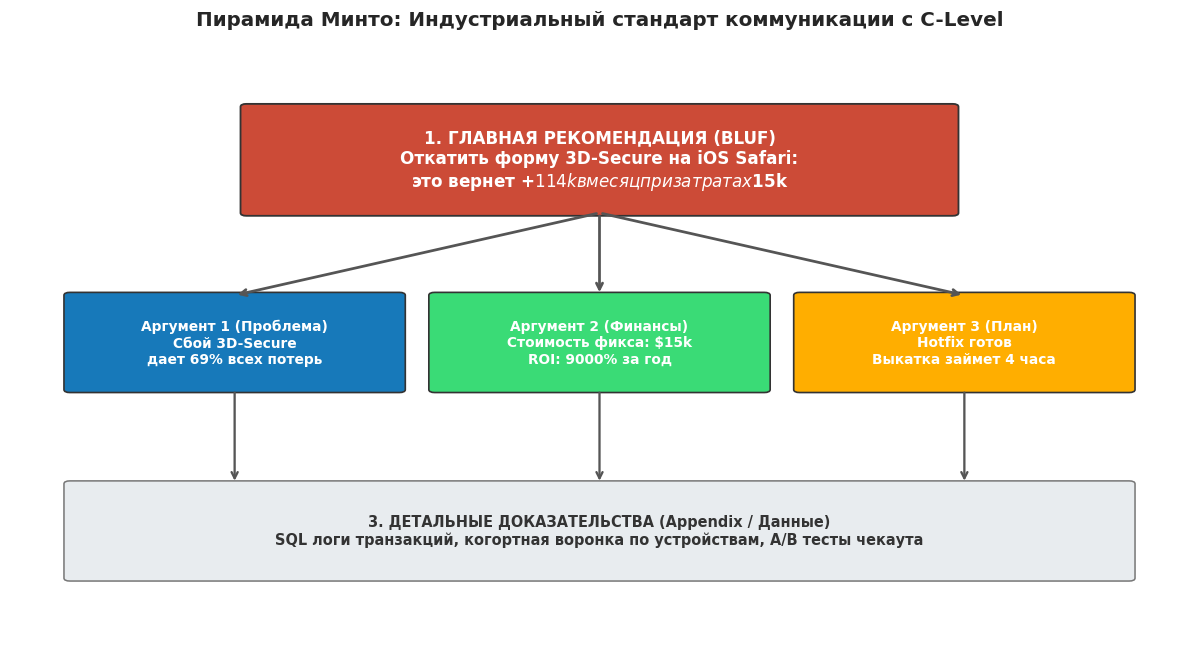

In [3]:
# Визуализация архитектуры Пирамиды Минто
fig, ax = plt.subplots(figsize=(11, 6), dpi=110)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis('off')

# Уровень 1: Главная мысль (BLUF)
rect1 = patches.FancyBboxPatch((20, 72), 60, 18, boxstyle="round,pad=0.5", 
                              facecolor=ALERT, edgecolor="#333333", linewidth=1.2)
ax.add_patch(rect1)
ax.text(50, 81, "1. ГЛАВНАЯ РЕКОМЕНДАЦИЯ (BLUF)\nОткатить форму 3D-Secure на iOS Safari:\nэто вернет +$114k в месяц при затратах $15k", 
        color='white', fontweight='bold', fontsize=11, ha='center', va='center')

# Уровень 2: 3 ключевых аргумента
args = [
    (5, 42, 28, "Аргумент 1 (Проблема)\nСбой 3D-Secure\nдает 69% всех потерь", PRIMARY),
    (36, 42, 28, "Аргумент 2 (Финансы)\nСтоимость фикса: $15k\nROI: 9000% за год", SUCCESS),
    (67, 42, 28, "Аргумент 3 (План)\nHotfix готов\nВыкатка займет 4 часа", WARNING)
]
for x, y, w, text, color in args:
    rect = patches.FancyBboxPatch((x, y), w, 16, boxstyle="round,pad=0.5", 
                                  facecolor=color, edgecolor="#333333", linewidth=1.1)
    ax.add_patch(rect)
    ax.text(x + w/2, y + 8, text, color='white', fontweight='bold', fontsize=9, ha='center', va='center')

# Уровень 3: База данных и доказательства
rect3 = patches.FancyBboxPatch((5, 10), 90, 16, boxstyle="round,pad=0.5", 
                              facecolor='#e8ecef', edgecolor="#767676", linewidth=1)
ax.add_patch(rect3)
ax.text(50, 18, "3. ДЕТАЛЬНЫЕ ДОКАЗАТЕЛЬСТВА (Appendix / Данные)\nSQL логи транзакций, когортная воронка по устройствам, A/B тесты чекаута", 
        color='#333333', fontweight='bold', fontsize=9.5, ha='center', va='center')

# Стрелки иерархии
for x in [19, 50, 81]:
    ax.annotate("", xy=(x, 58), xytext=(50, 72), arrowprops=dict(arrowstyle="->", color="#555555", lw=1.8))
    ax.annotate("", xy=(x, 26), xytext=(x, 42), arrowprops=dict(arrowstyle="->", color="#555555", lw=1.5))

ax.set_title("Пирамида Минто: Индустриальный стандарт коммуникации с C-Level", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет срока окупаемости фикса (Payback Period)
При ежемесячных потерях $114k и затратах на исправление $15k, рассчитайте срок окупаемости в днях (при 30 днях в месяце).

In [4]:
### ВАШ КОД ЗДЕСЬ
cost = 15000
daily_return = 114000 / 30
payback_days = cost / daily_return

print(f"Срок окупаемости хотфикса: {payback_days:.1f} дня!")

assert payback_days < 5, "Окупаемость должна наступить быстрее чем за 5 дней"
print("✅ Тест успешно пройден: сильнейший бизнес-аргумент для топ-менеджмента!")

Срок окупаемости хотфикса: 3.9 дня!
✅ Тест успешно пройден: сильнейший бизнес-аргумент для топ-менеджмента!


### 💡 Правило одного слайда (The So What? Test)
Каждый график на слайде для руководства должен содержать действие в заголовке.
Вместо *«Динамика конверсии по устройствам»* пишите: *«Конверсия на iOS упала на 12% из-за сбоя 3D-Secure — требуется срочный хотфикс»*.